<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/PSO_2D_anim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Otimização por Enxame de Partículas

**Objetivo:** Demonstrar a evolução do **Particle Swarm Optimization (PSO)** em um espaço bidimensional, com:
- **Mapa de calor em tons de cinza** da função objetivo;
- **Partículas coloridas por grupo**, com **setas de velocidade**;
- Parâmetros configuráveis: **inércia (w)**, **melhor pessoal (c1)** e **melhor de grupo (c2)**;
- Topologias **global** (gbest) e **de vizinhança** (lbest em anel) e **grupos/ilhas** (cada cor = um grupo).


In [ ]:

# %% [setup] Importações e utilidades
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from dataclasses import dataclass
from typing import Callable, Tuple, List, Literal, Optional
import math, random, time
from IPython.display import Image, display

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)

set_seed(42)



## 1) Função objetivo (2D)


In [ ]:

def ackley(xy: np.ndarray) -> float:
    x, y = xy[..., 0], xy[..., 1]
    a = 20.0; b = 0.2; c = 2*np.pi
    term1 = -a * np.exp(-b * np.sqrt(0.5 * (x*x + y*y)))
    term2 = -np.exp(0.5 * (np.cos(c*x) + np.cos(c*y)))
    return (term1 + term2 + a + np.e)

def rastrigin(xy: np.ndarray) -> float:
    x, y = xy[..., 0], xy[..., 1]
    return 20 + (x*x - 10*np.cos(2*np.pi*x)) + (y*y - 10*np.cos(2*np.pi*y))

FUNCAO = "ackley"  # "ackley" ou "rastrigin"
f_obj: Callable[[np.ndarray], float] = ackley if FUNCAO == "ackley" else rastrigin



## 2) Grade e heatmap (tons de cinza)


In [ ]:

XMIN, XMAX = -5.0, 5.0
YMIN, YMAX = -5.0, 5.0
GRID_N = 300

xv = np.linspace(XMIN, XMAX, GRID_N)
yv = np.linspace(YMIN, YMAX, GRID_N)
XX, YY = np.meshgrid(xv, yv)
GRID = np.stack([XX, YY], axis=-1)
FVAL = f_obj(GRID)
FVAL_NORM = (FVAL - FVAL.min()) / (FVAL.max() - FVAL.min() + 1e-12)



## 3) PSO — Implementação


In [ ]:

Topology = Literal["global","ring","groups"]

from dataclasses import dataclass

@dataclass
class PSOParams:
    w: float = 0.7
    c1: float = 1.5
    c2: float = 1.5
    vmax: float = 0.5
    topology: Topology = "global"
    ring_k: int = 2
    groups: int = 3
    seed: int = 42

@dataclass
class SwarmState:
    X: np.ndarray
    V: np.ndarray
    Pbest: np.ndarray
    Pbest_val: np.ndarray
    Gbest: np.ndarray
    Gbest_val: float
    group_id: np.ndarray

def init_swarm(N: int, params: PSOParams, box: Tuple[float,float,float,float]):
    set_seed(params.seed)
    xmin, xmax, ymin, ymax = box
    X = np.column_stack([
        np.random.uniform(xmin, xmax, size=N),
        np.random.uniform(ymin, ymax, size=N)
    ])
    V = np.random.uniform(-0.1, 0.1, size=(N,2))
    Pbest = X.copy()
    Pbest_val = np.array([f_obj(x) for x in X])
    gbest_idx = np.argmin(Pbest_val)
    Gbest = Pbest[gbest_idx].copy()
    Gbest_val = float(Pbest_val[gbest_idx])
    group_id = np.repeat(np.arange(params.groups), repeats=int(np.ceil(N/params.groups)))[:N]
    return SwarmState(X,V,Pbest,Pbest_val,Gbest,Gbest_val,group_id)

def clamp(val: np.ndarray, lo: float, hi: float) -> np.ndarray:
    return np.minimum(hi, np.maximum(lo, val))

def neighborhood_best(state: SwarmState, i: int, params: PSOParams) -> np.ndarray:
    if params.topology == "global":
        return state.Gbest
    elif params.topology == "ring":
        N = state.X.shape[0]; k = params.ring_k
        idxs = [(i + d) % N for d in range(-k, k+1)]
        vals = state.Pbest_val[idxs]
        return state.Pbest[idxs[np.argmin(vals)]]
    else:
        gid = state.group_id[i]
        members = np.where(state.group_id == gid)[0]
        vals = state.Pbest_val[members]
        return state.Pbest[members[np.argmin(vals)]]

def step_pso(state: SwarmState, params: PSOParams, box: Tuple[float,float,float,float]) -> None:
    xmin, xmax, ymin, ymax = box
    w, c1, c2 = params.w, params.c1, params.c2
    r1 = np.random.uniform(size=(state.X.shape[0], 2))
    r2 = np.random.uniform(size=(state.X.shape[0], 2))

    lbest = np.zeros_like(state.X)
    for i in range(state.X.shape[0]):
        lbest[i] = neighborhood_best(state, i, params)

    state.V = (w * state.V
               + c1 * r1 * (state.Pbest - state.X)
               + c2 * r2 * (lbest - state.X))
    state.V = clamp(state.V, -params.vmax, params.vmax)
    state.X = state.X + state.V
    state.X[:,0] = clamp(state.X[:,0], xmin, xmax)
    state.X[:,1] = clamp(state.X[:,1], ymin, ymax)

    vals = np.array([f_obj(x) for x in state.X])
    improved = vals < state.Pbest_val
    state.Pbest[improved] = state.X[improved]
    state.Pbest_val[improved] = vals[improved]

    gbest_idx = np.argmin(state.Pbest_val)
    if state.Pbest_val[gbest_idx] < state.Gbest_val:
        state.Gbest = state.Pbest[gbest_idx].copy()
        state.Gbest_val = float(state.Pbest_val[gbest_idx])



## 4) Animação


In [ ]:

def cores_bright(K: int):
    base = ['tab:orange','tab:blue','tab:green','tab:red','tab:purple','tab:pink','tab:brown','tab:olive','tab:cyan']
    return [base[i % len(base)] for i in range(K)]

def animar_pso(N: int = 40,
               params: PSOParams = PSOParams(w=0.70, c1=1.5, c2=1.5, vmax=0.25, topology="groups", ring_k=2, groups=3, seed=7),
               box: Tuple[float,float,float,float] = (XMIN, XMAX, YMIN, YMAX),
               steps: int = 120,
               save_gif: Optional[str] = None,
               interval_ms: int = 80):
    state = init_swarm(N, params, box)
    colors = cores_bright(params.groups)
    fig, ax = plt.subplots(figsize=(6,5))
    ax.imshow(FVAL_NORM, origin='lower', extent=(XMIN, XMAX, YMIN, YMAX), cmap='gray', alpha=0.95)

    scatters = []
    quivers = []
    for g in range(params.groups):
        idx = np.where(state.group_id == g)[0]
        s = ax.scatter(state.X[idx,0], state.X[idx,1], s=25, marker='o', color=colors[g], label=f'Grupo {g}')
        scatters.append((g, idx, s))
        q = ax.quiver(state.X[idx,0], state.X[idx,1], state.V[idx,0], state.V[idx,1],
                      angles='xy', scale_units='xy', scale=1.0, color=colors[g],
                      width=0.004, headlength=4, headaxislength=4, minlength=0.1)
        quivers.append((g, idx, q))

    gbest_dot = ax.scatter([state.Gbest[0]], [state.Gbest[1]], s=60, marker='*', color='yellow', edgecolor='k', zorder=3, label='gbest')

    ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX)
    ax.set_title(f"PSO — topologia={params.topology}, w={params.w:.2f}, c1={params.c1:.2f}, c2={params.c2:.2f}")
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlabel('x'); ax.set_ylabel('y')

    def update(frame):
        step_pso(state, params, box)
        for (g, idx, s), (_, idx2, q) in zip(scatters, quivers):
            s.set_offsets(state.X[idx])
            q.set_offsets(state.X[idx])
            U = state.V[idx,0]; Vv = state.V[idx,1]
            q.set_UVC(U, Vv)
        gbest_dot.set_offsets([state.Gbest])
        ax.set_title(f"Iter {frame+1}/{steps} — melhor f = {state.Gbest_val:.4f}")
        return [s for _,_,s in scatters] + [q for _,_,q in quivers] + [gbest_dot]

    anim = FuncAnimation(fig, update, frames=steps, interval=interval_ms, blit=False)
    plt.close(fig)

    if save_gif:
        try:
            anim.save(save_gif, writer=PillowWriter(fps=max(1, int(1000/interval_ms))))
        except Exception as e:
            print("Aviso: falha ao salvar GIF:", e)
    return anim



## 5) Experimentos guiados


In [ ]:

# Exemplo 1 — intensificação (global)
params1 = PSOParams(w=0.55, c1=0.2, c2=2.0, vmax=0.1, topology="global", groups=3, seed=10)
anim1 = animar_pso(N=45, params=params1, steps=100, save_gif='pso_global_intenso.gif', interval_ms=80)



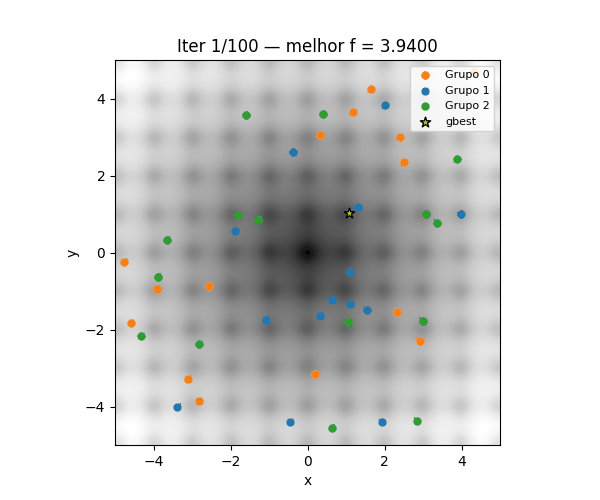

In [ ]:

with open('pso_global_intenso.gif', 'rb') as f:
  display(Image(data=f.read(), format='gif'))

In [ ]:
# Exemplo 2 — diversificação (grupos/ilhas)
params2 = PSOParams(w=0.90, c1=2.0, c2=0.2, vmax=0.1, topology="groups", groups=3, seed=11)
anim2 = animar_pso(N=45, params=params2, steps=100, save_gif='pso_groups_diverso.gif', interval_ms=80)


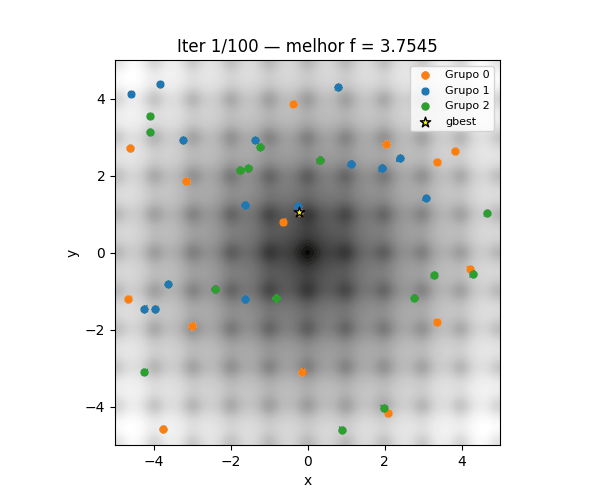

In [ ]:

with open('pso_groups_diverso.gif', 'rb') as f:
  display(Image(data=f.read(), format='gif'))


In [ ]:


# Exemplo 3 — ring
params3 = PSOParams(w=0.70, c1=1.7, c2=1.3, vmax=0.1, topology="ring", ring_k=2, groups=3, seed=12)
anim3 = animar_pso(N=45, params=params3, steps=100, save_gif='pso_ring_moderado.gif', interval_ms=80)


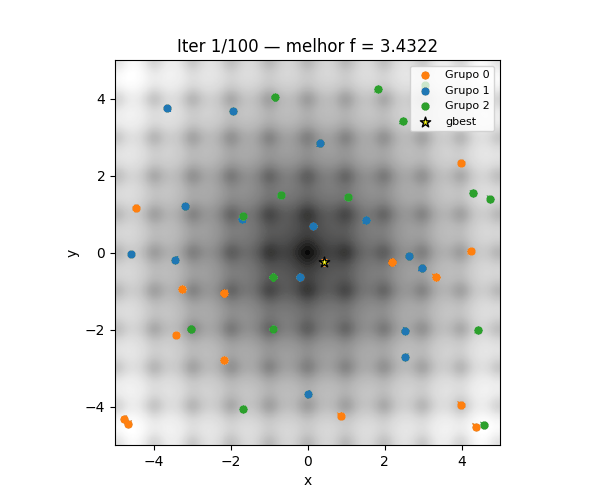

In [ ]:

with open('pso_ring_moderado.gif', 'rb') as f:
  display(Image(data=f.read(), format='gif'))


## 6) Mini *tuning* (rápido)


In [ ]:

def run_pso_once(params: PSOParams, steps: int = 150, N: int = 40) -> float:
    box = (XMIN, XMAX, YMIN, YMAX)
    S = init_swarm(N, params, box)
    for _ in range(steps):
        step_pso(S, params, box)
    return S.Gbest_val

configs = [
    PSOParams(w=0.55, c1=1.2, c2=2.0, topology="global"),
    PSOParams(w=0.90, c1=2.0, c2=0.8, topology="groups"),
    PSOParams(w=0.70, c1=1.7, c2=1.3, topology="ring", ring_k=2),
]

results = []
for cfg in configs:
    vals = [run_pso_once(cfg, steps=150, N=50) for _ in range(7)]
    results.append({
        "topologia": cfg.topology,
        "w": cfg.w, "c1": cfg.c1, "c2": cfg.c2,
        "mediana_fbest": float(np.median(vals)),
        "q1": float(np.percentile(vals,25)),
        "q3": float(np.percentile(vals,75))
    })

import pandas as pd
df_res = pd.DataFrame(results).sort_values('mediana_fbest')
df_res


,topologia,w,c1,c2,mediana_fbest,q1,q3
0,global,0.55,1.2,2.0,2.176037e-14,2.176037e-14,2.176037e-14
2,ring,0.70,1.7,1.3,7.701516e-09,7.701516e-09,7.701516e-09
1,groups,0.90,2.0,0.8,1.252705e-03,1.252705e-03,1.252705e-03



## 7) Exercícios sugeridos

1. Troque a função para `rastrigin` e compare as animações (multimodalidade mais evidente).
2. Compare topologias (`global` × `ring` × `groups`) mantendo `(w,c1,c2)` fixos. Discuta intensificação/diversificação.
3. Faça um grid de `(w,c1,c2)` pequeno (3×3×3), rode 5 vezes por configuração (sem animação) e reporte mediana/IQR.
4. Varie `vmax` e observe quando o enxame fica instável (oscilação persistente). Relacione com `w`.
5. Implemente um agendamento `w(t)` decrescente (linear) e compare com `w` constante.
